# Tarea 5 — SVM y Métodos de Validación

## Alerta anticipada de carga máxima en DAEWOO Steel Co.

**Proyecto:** *Sistema Predictivo de Gestión Energética y Alertas Operativas para DAEWOO Steel Co. mediante Minería de Datos y LangChain*

---

Integrantes: 


Académico:

Asignatura:

Sección:

Repositorio:
https://github.com/JoMi-MorV/Proyecto_Mineria_de_Datos_Daewoo

---

### Resumen

Este trabajo aplica **máquinas de vectores de soporte (SVM) con tres kernels distintos** (lineal, polinomial y RBF) a los datos del proyecto, y **valida cada uno con Cross Validation**. El problema es el de un sistema de alertas: **anticipar con una hora de antelación que la planta entrará en carga máxima** (`Maximum_Load`), usando lo que se conoce en el instante actual (consumo reciente, carga actual, mediciones eléctricas y calendario). Es la misma definición de pronóstico y las mismas variables de la Tarea 4, pero ahora el objetivo es binario (alerta / normal), que es la forma que necesita un sistema de alertas.

Los tres SVM se comparan entre sí, contra una regla simple de referencia (la persistencia) y bajo dos esquemas de validación cruzada: uno clásico (estratificado) y otro respetuoso del tiempo (temporal). El kernel se elige por validación cruzada, y el conjunto de prueba (octubre a diciembre de 2018) se usa solo para confirmar.

**Resultados principales** (detalle en las secciones 5 a 9):

- Los tres SVM superan claramente a la persistencia: en prueba, el F1 de la clase alerta sube de **0,559** (persistencia) a **0,680 a 0,735** según el kernel.
- El **kernel polinomial de grado 3** es el que mejor funciona en conjunto (mejor F1 y mejor AUC en prueba, y el mejor F1 en la validación estratificada). Con la validación temporal, el polinomial y el RBF quedan empatados dentro del margen de error.
- La validación cruzada **estratificada es optimista** (F1 de 0,85 para el polinomial frente a 0,72 en prueba), porque las lecturas cada 15 minutos son casi idénticas a sus vecinas. La validación temporal es más realista.
- Dos **anexos opcionales** (A y B) comprueban con experimentos dos explicaciones del texto principal y dejan conclusiones para el modelo final: con qué datos conviene entrenarlo y con qué cuidado elegir sus hiperparámetros. No son parte de lo que pide la tarea y pueden omitirse.

---

### Contenido

1. Introducción y contexto
2. Metodología
3. Preparación de los datos
4. Línea base: persistencia
5. SVM con tres kernels (partición entrenamiento y prueba)
6. El hiperplano en pantalla: efecto del kernel
7. Cross Validation estratificada
8. Cross Validation temporal
9. Ajuste de hiperparámetros y evaluación final
10. Conclusiones, limitaciones y próximos pasos
11. Anexos opcionales (A y B)

## 1. Introducción y contexto

### 1.1 El problema y su utilidad real

La planta de DAEWOO Steel Co. registra su consumo eléctrico **cada 15 minutos** durante todo 2018 (**35.040 mediciones**). Cada medición trae una etiqueta, `Load_Type`, que indica el nivel de carga de la planta: liviana, media o **máxima**. Los periodos de carga máxima son los de mayor exigencia y, en general, los de mayor costo, porque las tarifas eléctricas industriales suelen penalizar la demanda punta.

Clasificar la carga *del momento actual* no sirve: la planta ya mide su consumo en tiempo real y sabe en qué régimen está. La utilidad aparece al **anticipar**: si el sistema avisa con una hora de antelación que se viene una carga máxima, quien opera la planta puede actuar antes (por ejemplo, escalonar el encendido de equipos). Esa es la parte de **alertas operativas** del proyecto.

### 1.2 Qué se hace en esta tarea

- **Clase 1 (alerta):** la planta estará en `Maximum_Load` dentro de 1 hora.
- **Clase 0 (normal):** estará en `Light_Load` o `Medium_Load`.
- Se entrena un **SVM con tres kernels** y se valida cada uno con **Cross Validation**, para decidir con qué kernel se construiría la alerta del sistema final.

### 1.3 Relación con las tareas anteriores

La Tarea 4 pronosticó el nivel de carga en tres clases con árboles, Random Forest, AdaBoost y redes bayesianas. Aquí se reutilizan **exactamente las mismas 13 variables y la misma partición cronológica** (`src/modelos_aprendizaje/pronostico.py`), de modo que ambos trabajos parten de la misma información. Una diferencia importante es que aquí el objetivo es **binario** (alerta o normal) y en la Tarea 4 eran tres clases, por lo que las métricas de ambos trabajos no se pueden comparar directamente: para hacerlo habría que medir, en los modelos de la Tarea 4, el recall y la precisión de la clase `Maximum_Load`.

## 2. Metodología

### 2.1 Definición del pronóstico

- **Instante de origen (t):** el momento en que se hace el pronóstico. Solo se usa información de t y de instantes anteriores.
- **Horizonte:** 4 intervalos de 15 minutos = **1 hora**.
- **Objetivo (`y`):** 1 si en t + 1 h la planta está en `Maximum_Load`; 0 en caso contrario.
- **Partición:** el entrenamiento usa los instantes pronosticados anteriores al 1 de octubre de 2018 y la prueba usa los de octubre a diciembre. No se mezclan periodos.

### 2.2 Variables

Son las 13 variables de la Tarea 4, todas conocidas en el instante t: consumo previo (actual, de hace 15 min, de hace 1 h y de hace 24 h, variación en la última hora y carga actual), mediciones eléctricas (potencias reactivas y factores de potencia) y calendario del instante que se pronostica (tipo de día y hora, esta última como seno y coseno para que 23:45 y 00:00 queden cerca). No se usan `Usage_kWh` del instante pronosticado ni `CO2`.

### 2.3 SVM, hiperplano y kernels

Un SVM aprende, a partir de ejemplos pasados con su etiqueta conocida, **el hiperplano que separa las dos clases con el mayor margen posible**. Los **vectores de soporte** son los puntos más cercanos a la frontera, y son los únicos que la definen. Predecir consiste en ver de qué lado del hiperplano cae un punto nuevo: la regla aprendida es `f(x) = w·x + b`, y si `f(x) > 0` se emite la alerta. La distancia al hiperplano indica qué tan segura es la predicción.

El **kernel** decide qué forma puede tener esa frontera:

| Kernel | Frontera | Idea |
|---|---|---|
| **Lineal** | Plano recto | Funciona si la carga máxima se separa con un umbral combinado de variables. |
| **Polinomial** (grado 3) | Curva suave | Incorpora interacciones entre variables (por ejemplo, consumo y hora juntos). |
| **RBF** (gaussiano) | Curva flexible y local | Se adapta a la forma de los datos; es el más sensible a sus parámetros. |

Dos decisiones de implementación (en `modelos_svm.py`):

- El SVM es sensible a la escala, por lo que cada modelo es un `Pipeline` con `StandardScaler` + `SVC`. El escalador se ajusta solo con los datos de entrenamiento de cada fold.
- Como la clase alerta es minoritaria (alrededor de 21 %), se usa `class_weight="balanced"`, que pondera más esa clase para que el modelo no aprenda a decir siempre "normal".

### 2.4 Cross Validation

La validación cruzada de k folds divide los datos en k partes; cada una hace de prueba una vez mientras el modelo se entrena con las otras k − 1. Se reporta el promedio y la desviación de cada métrica: el promedio dice qué tan bien funciona el SVM y la desviación, qué tan estable es. Se usa **k = 5** en dos esquemas, siempre solo con el conjunto de entrenamiento:

- **Estratificado:** folds al azar que conservan la proporción de alertas. Es el esquema clásico.
- **Temporal:** se entrena con el pasado y se valida con el futuro, dejando un hueco de 1 día entre ambos. Es más exigente y más realista, porque las lecturas vecinas (cada 15 min) se parecen mucho y mezclarlas al azar puede dar resultados optimistas.

### 2.5 Métricas

Como solo el 21 % de los casos son alertas, la exactitud engaña (decir siempre "normal" da 79 %). Se reportan las métricas de la clase alerta:

- **Recall:** de las cargas máximas reales, cuántas se anticiparon.
- **Precisión:** de las alertas emitidas, cuántas eran reales (1 − falsas alarmas).
- **F1:** equilibrio entre recall y precisión; es la métrica principal para comparar.
- **AUC:** qué tan bien ordena el modelo los casos (distancia al hiperplano), sin fijar un umbral.

Las tablas traen además otras columnas:

- **Exactitud:** porcentaje de aciertos totales (engañosa por el desbalance, como se explicó).
- **Exactitud_balanceada:** promedio del recall de cada clase (alerta y normal); no se deja engañar por el desbalance.
- **AP (average precision):** resumen de la curva precisión-recall. Como el AUC no depende del umbral, pero es más exigente con la clase minoritaria.
- **Vectores_soporte:** cantidad de puntos que definen el hiperplano.
- **Seg_entrenamiento / Seg_por_fold:** segundos que toma ajustar el modelo.

## 3. Preparación de los datos

Se carga el dataset limpio de la Tarea 2 y se construyen las variables del pronóstico (la lógica está en `src/modelos_aprendizaje/pronostico.py`; el objetivo binario se arma en `src/SVM_CV/datos.py`).

In [1]:
# Celda 3.1: carga de datos y construcción del problema de alerta
import sys, warnings
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from SVM_CV import datos, modelos_svm as ms, validacion_cruzada as vc, graficos as gr
from modelos_aprendizaje import pronostico as pr

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", None)   # que no se corten los textos de las tablas

HORIZONTE = 4      # 4 intervalos de 15 min = 1 hora
K_FOLDS = 5        # folds de la validación cruzada

df = datos.cargar_dataset_limpio()
X_tr, X_te, y_tr, y_te, info = datos.construir_problema(df, horizonte=HORIZONTE)

print(f"Dataset limpio: {len(df):,} filas".replace(",", "."))
print(f"Entrenamiento: {len(X_tr):,} casos | instantes pronosticados del "
      f"{info['fecha_objetivo_tr'].min():%d-%m-%Y} al {info['fecha_objetivo_tr'].max():%d-%m-%Y}".replace(",", "."))
print(f"Prueba:        {len(X_te):,} casos | instantes pronosticados del "
      f"{info['fecha_objetivo_te'].min():%d-%m-%Y} al {info['fecha_objetivo_te'].max():%d-%m-%Y}".replace(",", "."))
print(f"Filas descartadas por falta de historial o de futuro: {info['n_filas_descartadas']}")
display(datos.resumen_clases(y_tr, y_te))
display(pr.tabla_variables(X_tr))

Dataset limpio: 35.040 filas
Entrenamiento: 26.108 casos | instantes pronosticados del 02-01-2018 al 30-09-2018
Prueba:        8.832 casos | instantes pronosticados del 01-10-2018 al 31-12-2018
Filas descartadas por falta de historial o de futuro: 100


,Conjunto,Casos,Normal (0),Alerta (1),% Alerta
0,Entrenamiento,26108,20660,5448,20.867
1,Prueba,8832,7008,1824,20.652


,Variable,Grupo,Qué representa
0,Consumo_t,Consumo previo,Consumo actual (kWh)
1,Consumo_t-15min,Consumo previo,Consumo de hace 15 minutos (kWh)
2,Consumo_t-1h,Consumo previo,Consumo de hace 1 hora (kWh)
3,Consumo_t-24h,Consumo previo,Consumo a la misma hora de ayer (kWh)
4,Variacion_1h,Consumo previo,Consumo actual − consumo hace 1 h (tendencia)
5,Carga_actual,Consumo previo,"Nivel de carga actual (0 liviana, 1 media, 2 máxima)"
6,Lagging_Current_Reactive.Power_kVarh,Mediciones eléctricas,Energía reactiva inductiva actual
7,Leading_Current_Reactive_Power_kVarh,Mediciones eléctricas,Energía reactiva capacitiva actual
8,Lagging_Current_Power_Factor,Mediciones eléctricas,Factor de potencia inductivo actual
9,Leading_Current_Power_Factor,Mediciones eléctricas,Factor de potencia capacitivo actual


**Qué muestra.** El tamaño y el rango de fechas de cada conjunto, cuántos casos de alerta hay en cada uno y la lista de las 13 variables con su grupo.

**Cómo interpretarlo.**

- El entrenamiento debe terminar a fines de septiembre y la prueba empezar el 1 de octubre: es la verificación de que no se mezclan periodos.
- La proporción de alertas es casi igual en ambos conjuntos (alrededor de 21 %), de modo que la prueba no está sesgada hacia una clase. Pero **la clase está desbalanceada**, por lo que un modelo que siempre dijera "normal" acertaría el 79 % de las veces sin servir para nada. Por eso se evalúa con recall, precisión y F1.

**Resultados.** Quedaron **26.108** casos de entrenamiento (5.448 alertas, 20,9 %) y **8.832** de prueba (1.824 alertas, 20,7 %), tras descartar 100 filas (96 sin las 24 h de historia previa y 4 sin un "dentro de 1 hora" que pronosticar).

## 4. Línea base: persistencia

Antes de entrenar modelos hay que fijar la vara. La regla más simple de un sistema de alertas es la **persistencia**: *"habrá carga máxima dentro de 1 hora si ahora ya hay carga máxima"*. No aprende nada y no necesita un modelo. **Todo SVM debe superarla** para justificar su existencia.

In [2]:
# Celda 4.1: desempeño de la persistencia en el conjunto de prueba
pred_base = datos.linea_base_persistencia(X_te, y_te)
met_base = ms.metricas_clasificacion(y_te, pred_base)
display(pd.Series(met_base, name="Persistencia").to_frame().T)
display(ms.matriz_confusion(y_te, pred_base))

,Exactitud,Exactitud_balanceada,Recall,Precision,F1
Persistencia,0.818,0.722,0.559,0.559,0.559


,Pred: Normal,Pred: Alerta
Real: Normal,6204,804
Real: Alerta,804,1020


**Cómo leer la tabla.** La matriz de confusión tiene en las filas lo que ocurrió y en las columnas lo que se predijo. La esquina inferior derecha son las alertas bien anticipadas; la inferior izquierda son cargas máximas que no se avisaron; la superior derecha son falsas alarmas.

**Resultados.** La persistencia alcanza una exactitud de 0,818, pero **recall = precisión = F1 = 0,559**: solo "acierta" el 55,9 % de las cargas máximas, y lo hace sobre todo cuando la planta ya estaba en carga máxima y se mantiene. Es la referencia que los SVM deben batir.

## 5. SVM con tres kernels (partición entrenamiento y prueba)

Primero se entrenan los tres SVM con sus hiperparámetros por defecto (`C = 1`; `gamma = "scale"`; grado 3 en el polinomial) sobre todo el entrenamiento y se evalúan en la prueba, que es información que los modelos nunca vieron. Esta es la referencia con la que se contrastará después la validación cruzada.

,Exactitud,Exactitud_balanceada,Recall,Precision,F1,AUC,AP,Vectores_soporte,Seg_entrenamiento
Kernel,,,,,,,,,
lineal,0.849,0.823,0.780,0.603,0.680,0.898,0.616,5932,8.596
polinomial,0.878,0.836,0.764,0.682,0.721,0.922,0.743,3969,4.605
rbf,0.862,0.835,0.790,0.633,0.703,0.906,0.734,4577,3.954


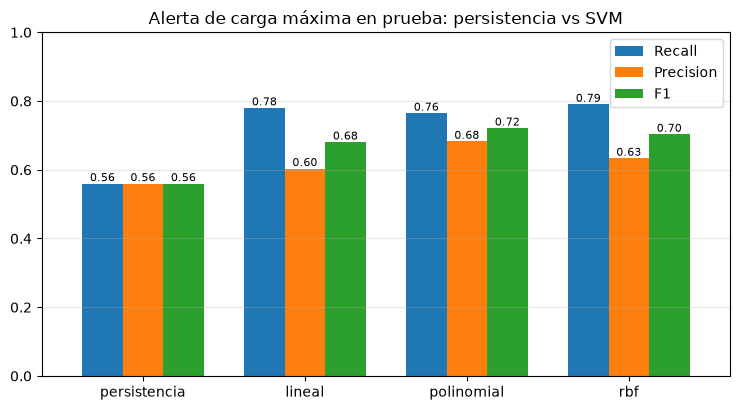

In [3]:
# Celda 5.1: entrenamiento de los tres SVM y evaluación en prueba
tabla_ho, modelos_ho, preds_ho = ms.comparar_kernels_holdout(X_tr, X_te, y_tr, y_te)
display(tabla_ho)

comp = tabla_ho[["Recall", "Precision", "F1"]].copy()
comp.loc["persistencia"] = [met_base["Recall"], met_base["Precision"], met_base["F1"]]
fig = gr.graficar_comparacion(comp.loc[["persistencia", "lineal", "polinomial", "rbf"]],
                              titulo="Alerta de carga máxima en prueba: persistencia vs SVM")
plt.show()

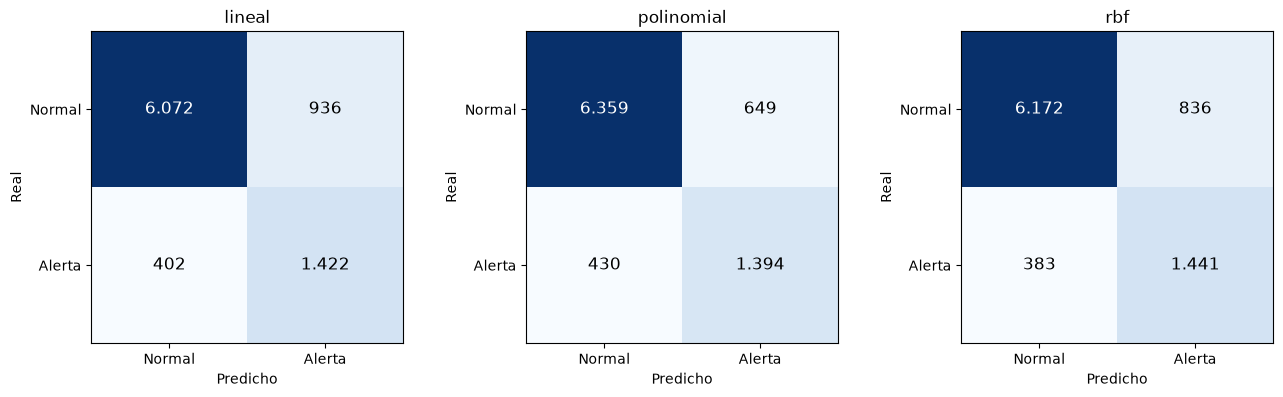

In [4]:
# Celda 5.2: matrices de confusión de los tres kernels (prueba)
fig = gr.graficar_matrices_confusion(y_te, preds_ho)
plt.show()

**Cómo leer la tabla.** Cada fila es un kernel. `Vectores_soporte` es la cantidad de puntos que definen el hiperplano del modelo de 13 variables (menos significa una frontera más simple) y `Seg_entrenamiento` el tiempo de ajuste. Las demás columnas se definen en la sección 2.5.

**Cómo leer el gráfico de barras.** Cada grupo de barras es un modelo y cada color una métrica: azul = recall, naranja = precisión y verde = F1 (las cifras sobre las barras están redondeadas a 2 decimales). En la persistencia las tres barras valen lo mismo (0,56). Lo que hay que mirar es cuánto sube cada color al pasar a un SVM: las barras azules (recall) suben bastante más que las naranjas (precisión).

**Qué comparar.** (1) Los SVM frente a la persistencia (gráfico de barras). (2) Entre kernels: el recall mide cuántas cargas máximas se anticipan y la precisión cuántas alertas son reales; el F1 las resume. (3) En las matrices de confusión, el costo de cada kernel en falsas alarmas (arriba a la derecha) y en alertas no emitidas (abajo a la izquierda).

**Resultados** (de 1.824 cargas máximas reales en la prueba):

| Kernel | Recall | Precisión | F1 | AUC | Alertas bien anticipadas | Falsas alarmas |
|---|---|---|---|---|---|---|
| Persistencia | 0,559 | 0,559 | 0,559 | — | 1.020 | 804 |
| Lineal | 0,780 | 0,603 | 0,680 | 0,898 | 1.422 | 936 |
| Polinomial | 0,764 | **0,682** | **0,721** | **0,922** | 1.394 | **649** |
| RBF | **0,790** | 0,633 | 0,703 | 0,906 | **1.441** | 836 |

- **Los tres SVM superan a la persistencia, sobre todo en recall:** anticipan entre 20 y 23 puntos porcentuales más de las cargas máximas (recall 0,76 a 0,79 frente a 0,56). La precisión sube bastante menos (de 0,56 a 0,60 en el lineal, 0,63 en el RBF y 0,68 en el polinomial, es decir, de 4 a 12 puntos): los SVM emiten más alertas y no todas son reales. Aun así, el F1 sube de 0,56 a entre 0,68 y 0,72.
- **El polinomial es el mejor equilibrio**: mayor F1 y AUC y la menor cantidad de falsas alarmas (649), a costa de anticipar algo menos que el RBF (1.394 frente a 1.441). El RBF es el que más cargas máximas anticipa, pero con más falsas alarmas.
- **El lineal es el más débil** en F1 y AUC y además necesita casi 6.000 vectores de soporte (frente a unos 4.000 a 4.600), lo que indica que un plano recto no separa bien las clases.

## 6. El hiperplano en pantalla: efecto del kernel

Con 13 variables el hiperplano no se puede dibujar. Para **ver** qué hace cada kernel se reentrena cada SVM solo con **dos variables**: el consumo actual y la hora del instante pronosticado. Este gráfico es ilustrativo (no es el modelo final), pero muestra con claridad cómo cambia la frontera de decisión. Se apilan los tres kernels (uno debajo del otro) y se usa una muestra de 1.500 puntos del entrenamiento para que el gráfico sea legible.

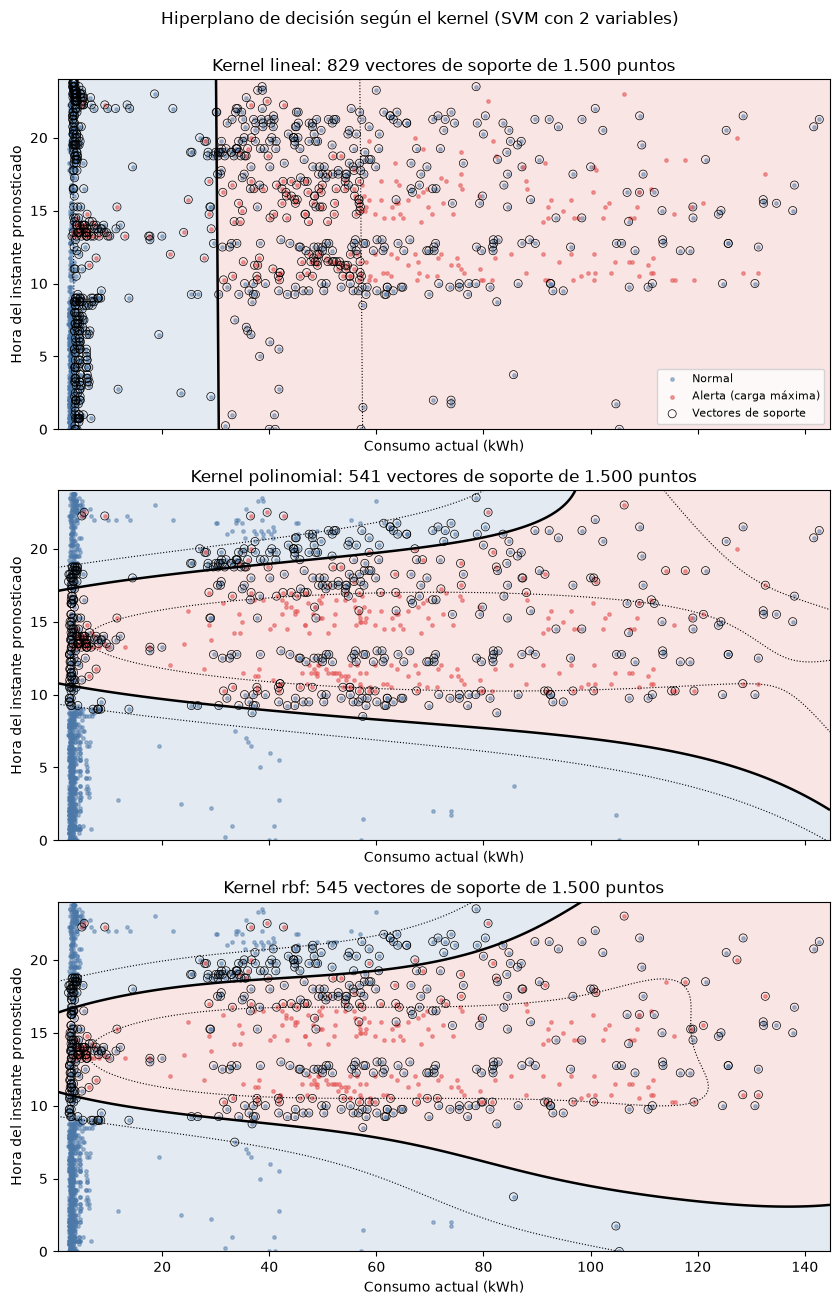

In [5]:
# Celda 6.1: frontera de decisión de los tres kernels en 2 variables
fig = gr.graficar_frontera_2d(X_tr, y_tr)
plt.show()

**Cómo leer el gráfico.** Hay un panel por kernel. El fondo rojo es la zona que el modelo clasifica como alerta y el azul como normal. La línea negra continua es el **hiperplano** (`f(x) = 0`); las punteadas son los **márgenes** (`f(x) = ±1`). Los círculos son los **vectores de soporte**: los puntos que están sobre el margen, dentro de él o del lado equivocado, y que son los únicos que definen la frontera.

**Un aviso sobre los números del título.** Los vectores de soporte que aparecen en cada panel (829, 541 y 545) pertenecen a estos modelos de **2 variables entrenados con 1.500 puntos**. No son los de la tabla de la sección 5 (5.932, 3.969 y 4.577), que corresponden al modelo de 13 variables entrenado con los 26.108 casos. Lo que se conserva es el orden: el lineal necesita más vectores de soporte que los otros dos.

**Qué muestra.**

- **Lineal:** la frontera es una recta casi vertical, en unos 31 kWh sin importar la hora. Solo separa por consumo y **no puede aprender que la carga máxima ocurre en horario diurno** (el 93 % de las alertas del entrenamiento ocurre entre las 10 y las 19 horas). Por eso marca como alerta todo lo que supera los 31 kWh aunque sea de madrugada o de noche; en esos casos fuera de horario, el 90 % en realidad son normales. La franja de círculos pegada al borde izquierdo son lecturas de consumo casi nulo (más de la mitad de las lecturas tiene menos de 5 kWh), que quedan sobre el margen izquierdo de la recta (en unos 3 kWh).
- **Polinomial y RBF:** la frontera se curva y delimita una **zona de alerta que combina consumo y hora**: consumo alto y horario diurno. Es justo la interacción que el kernel lineal no puede representar. Las dos curvas se parecen mucho; la diferencia visible está a la derecha: el RBF cierra la zona de alerta alrededor de los 120 kWh (línea punteada) y el polinomial la deja abierta.
- **Consumo muy alto (sobre unos 100 kWh):** ambos kernels amplían la zona de alerta hacia casi todas las horas. Ahí hay pocos puntos (solo el 5 % de las lecturas supera 100 kWh), por lo que esa parte de la frontera es una extrapolación y no debe leerse como un hallazgo.

Esto explica con una imagen por qué los kernels curvos rinden mejor en la sección 5: la carga máxima depende de la **combinación** de consumo y hora, no de cada una por separado.

## 7. Cross Validation estratificada

Un solo corte entrenamiento/prueba puede favorecer a un kernel por azar. Se valida cada SVM con **5 folds estratificados** sobre el entrenamiento: en cada fold se ajustan el escalador y el modelo con 4 partes y se evalúa en la quinta. También se mide la persistencia sobre los mismos folds.

,Recall,Precision,F1,AUC,Seg_por_fold
Kernel,,,,,
lineal,0.932 ± 0.002,0.681 ± 0.009,0.787 ± 0.007,0.945 ± 0.002,4.850
polinomial,0.972 ± 0.006,0.760 ± 0.013,0.853 ± 0.010,0.979 ± 0.001,2.530
rbf,0.972 ± 0.005,0.721 ± 0.006,0.828 ± 0.005,0.977 ± 0.001,2.380


Persistencia (mismos folds): Recall 0.633 | Precisión 0.633 | F1 0.633 ± 0.008

F1 por fold:


,lineal,polinomial,rbf
fold_1,0.793,0.858,0.832
fold_2,0.788,0.860,0.830
fold_3,0.794,0.861,0.832
fold_4,0.781,0.842,0.822
fold_5,0.780,0.842,0.823


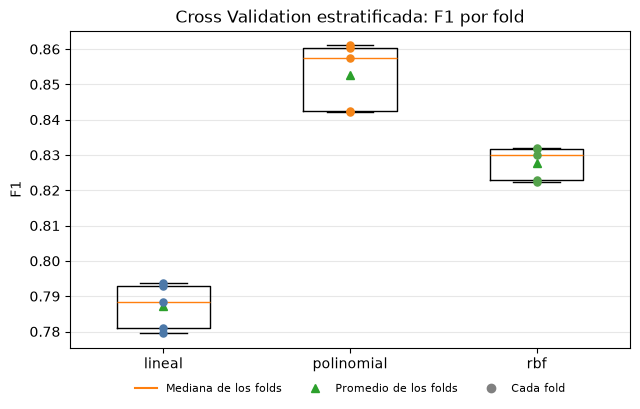

Mejor kernel según F1 medio: polinomial


In [6]:
# Celda 7.1: Cross Validation estratificada de los tres kernels
medias_e, desv_e, folds_e = vc.comparar_kernels_cv(X_tr, y_tr, esquema="estratificado", k=K_FOLDS)
display(vc.formatear_media_desv(medias_e, desv_e))

base_m_e, base_s_e = vc.linea_base_cv(X_tr, y_tr, esquema="estratificado", k=K_FOLDS)
print(f"Persistencia (mismos folds): Recall {base_m_e['Recall']:.3f} | "
      f"Precisión {base_m_e['Precision']:.3f} | F1 {base_m_e['F1']:.3f} ± {base_s_e['F1']:.3f}")

print("\nF1 por fold:")
display(pd.DataFrame({n: f["F1"] for n, f in folds_e.items()}))
fig = gr.graficar_metricas_cv(folds_e, "F1", "Cross Validation estratificada: F1 por fold")
plt.show()
print("Mejor kernel según F1 medio:", vc.mejor_kernel(medias_e, "F1"))

**Cómo leer la tabla.** Cada celda es `promedio ± desviación estándar` de los 5 folds. El promedio indica el nivel de desempeño; la desviación, la estabilidad. En el boxplot, la **caja** abarca del 25 % al 75 % de los folds, la **línea naranja** es la mediana, el **triángulo verde** el promedio y cada **punto** es uno de los 5 folds.

**Qué comparar.** Si las diferencias entre kernels son mayores que la desviación (cajas que no se solapan), la diferencia es real; si son menores, podría ser ruido.

**Resultados.**

| Kernel | Recall | Precisión | F1 | AUC |
|---|---|---|---|---|
| Lineal | 0,932 ± 0,002 | 0,681 ± 0,009 | 0,787 ± 0,007 | 0,945 ± 0,002 |
| Polinomial | 0,972 ± 0,006 | **0,760 ± 0,013** | **0,853 ± 0,010** | **0,979 ± 0,001** |
| RBF | 0,972 ± 0,005 | 0,721 ± 0,006 | 0,828 ± 0,005 | 0,977 ± 0,001 |
| Persistencia | 0,633 | 0,633 | 0,633 ± 0,008 | — |

- Con este esquema el **polinomial es el mejor** y la diferencia con el RBF (0,853 frente a 0,828) y con el lineal (0,787) es varias veces mayor que la desviación, así que no es ruido.
- Las desviaciones son muy pequeñas: el resultado es **muy estable entre folds**.
- **Cuidado:** estos números son **demasiado buenos** (recall de 0,97 frente a 0,76 a 0,79 en la prueba de la sección 5). La razón: los folds se arman al azar, de modo que una lectura de las 14:15 queda en el entrenamiento y la de las 14:30 en la validación, y ambas son casi idénticas. El modelo "ha visto" a los vecinos de cada caso que evalúa. Esto se verifica en la sección siguiente.

## 8. Cross Validation temporal

Aquí cada fold entrena con el **pasado** y valida con el **futuro** inmediato (con un hueco de un día para que no haya lecturas vecinas a ambos lados). Es cómo se usaría el modelo en la planta, y no permite que el modelo "vea" lecturas contiguas a las que evalúa. Los folds usan ventanas crecientes: el primero entrena con muy pocos meses y el último con casi todo.

,Recall,Precision,F1,AUC,Seg_por_fold
Kernel,,,,,
lineal,0.967 ± 0.060,0.660 ± 0.116,0.782 ± 0.101,0.941 ± 0.027,2.320
polinomial,0.912 ± 0.144,0.708 ± 0.161,0.795 ± 0.154,0.941 ± 0.055,1.380
rbf,0.922 ± 0.123,0.701 ± 0.156,0.794 ± 0.144,0.936 ± 0.062,1.360


Persistencia (mismos folds): Recall 0.659 | Precisión 0.659 | F1 0.659 ± 0.017

F1 por fold (el fold 1 entrena con la menor cantidad de datos):


,lineal,polinomial,rbf
fold_1,0.635,0.527,0.548
fold_2,0.719,0.797,0.784
fold_3,0.844,0.888,0.884
fold_4,0.857,0.878,0.883
fold_5,0.856,0.883,0.874


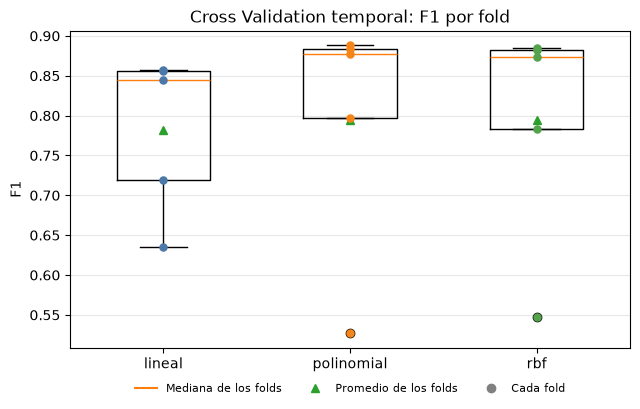

In [7]:
# Celda 8.1: Cross Validation temporal de los tres kernels
medias_t, desv_t, folds_t = vc.comparar_kernels_cv(X_tr, y_tr, esquema="temporal", k=K_FOLDS)
display(vc.formatear_media_desv(medias_t, desv_t))

base_m_t, base_s_t = vc.linea_base_cv(X_tr, y_tr, esquema="temporal", k=K_FOLDS)
print(f"Persistencia (mismos folds): Recall {base_m_t['Recall']:.3f} | "
      f"Precisión {base_m_t['Precision']:.3f} | F1 {base_m_t['F1']:.3f} ± {base_s_t['F1']:.3f}")

print("\nF1 por fold (el fold 1 entrena con la menor cantidad de datos):")
display(pd.DataFrame({n: f["F1"] for n, f in folds_t.items()}))
fig = gr.graficar_metricas_cv(folds_t, "F1", "Cross Validation temporal: F1 por fold")
plt.show()

In [8]:
# Celda 8.2: ¿qué esquema se parece más a lo que ocurre en la prueba?
display(pd.DataFrame({
    "F1 CV estratificada": medias_e["F1"],
    "F1 CV temporal": medias_t["F1"],
    "F1 prueba (oct-dic)": tabla_ho["F1"],
}))

,F1 CV estratificada,F1 CV temporal,F1 prueba (oct-dic)
Kernel,,,
lineal,0.787,0.782,0.680
polinomial,0.853,0.795,0.721
rbf,0.828,0.794,0.703


**Cómo leer las tablas.** Misma estructura de la sección 7. La segunda tabla pone lado a lado el F1 que entrega cada esquema de validación y el F1 real de la prueba: el esquema que más se acerca a la prueba es el que mejor predice cómo se comportará el modelo en producción.

**Resultados.**

| Kernel | Recall | Precisión | F1 | AUC |
|---|---|---|---|---|
| Lineal | 0,967 ± 0,060 | 0,660 ± 0,116 | 0,782 ± 0,101 | 0,941 ± 0,027 |
| Polinomial | 0,912 ± 0,144 | 0,708 ± 0,161 | 0,795 ± 0,154 | 0,941 ± 0,055 |
| RBF | 0,922 ± 0,123 | 0,701 ± 0,156 | 0,794 ± 0,144 | 0,936 ± 0,062 |
| Persistencia | 0,659 | 0,659 | 0,659 ± 0,017 | — |

- **Las desviaciones se multiplican** (de 0,01 a 0,10 o 0,15). Los folds temporales son muy distintos entre sí. En el boxplot, el primer fold del polinomial (0,53) y del RBF (0,55) queda aislado muy por debajo de su caja, y el lineal tiene dos folds bajos (0,64 y 0,72). El primer fold entrena solo con enero y la primera mitad de febrero, y valida desde mediados de febrero hasta abril.
- **El promedio y la mediana cuentan historias distintas.** En el polinomial y el RBF, el triángulo verde (promedio, 0,795 y 0,794) queda muy por debajo de la línea naranja (mediana, 0,878 y 0,874) porque el primer fold los arrastra hacia abajo; en el lineal la mediana es 0,844. **Los dos kernels curvos superan al lineal en 4 de los 5 folds** (todos menos el primero; F1 de 0,78 a 0,89 frente a 0,72 a 0,86). Solo en el primer fold rinde mejor el lineal. El Anexo A (opcional) muestra que la causa no es la cantidad de casos, sino que esas primeras semanas no representan bien el periodo que viene después.
- **En promedio, los tres kernels quedan empatados** dentro del margen de error (F1 de 0,78 a 0,80). La ventaja clara del polinomial en la sección 7 no se sostiene con esta validación, aunque el empate se debe en buena parte a ese primer fold.
- **Todos superan a la persistencia** (0,659) también aquí.
- **Comparación con la prueba (celda 8.2).** La estratificada da F1 de 0,79 a 0,85 y la temporal de 0,78 a 0,80, mientras que la prueba da 0,68 a 0,72: **la validación estratificada sobreestima el desempeño real en 0,11 a 0,13 puntos; la temporal, en unos 0,07 a 0,10.** Ninguna iguala a la prueba, por lo que conviene leer la validación cruzada como una forma de **ordenar los kernels y de ver la estabilidad**, no como la predicción exacta del desempeño. Una parte de la diferencia puede deberse a que octubre a diciembre sea un periodo algo más difícil, algo que con un solo año de datos no se puede descartar.

## 9. Ajuste de hiperparámetros y evaluación final

Hasta aquí cada kernel usó sus parámetros por defecto, y eso podría favorecer o perjudicar a alguno. Se hace una búsqueda en grilla pequeña por kernel (`C` en los tres; grado 2 o 3 en el polinomial; `gamma` en el RBF), eligiendo la mejor combinación por el **F1 de la validación cruzada temporal** (el esquema más realista). Para que sea rápido se usa una submuestra estratificada de 8.000 casos del entrenamiento, y después se reentrena cada kernel con todo el entrenamiento y se evalúa en la prueba.

In [9]:
# Celda 9.1: búsqueda de hiperparámetros por kernel (CV temporal, submuestra de 8.000 casos)
N_AJUSTE = 8000
X_aj, y_aj = datos.submuestra_estratificada(X_tr, y_tr, N_AJUSTE)
mejores, tablas_aj = vc.ajustar_todos(X_aj, y_aj, esquema="temporal", k=K_FOLDS, scoring="f1")

print("Mejores hiperparámetros por kernel:")
for n, p in mejores.items():
    print(f"  {n:11s} {p}")
for n, t in tablas_aj.items():
    print(f"\nMejores combinaciones - {n}:")
    display(t.head(5))

Mejores hiperparámetros por kernel:
  lineal      {'C': 1}
  polinomial  {'C': 10, 'degree': 3}
  rbf         {'C': 10, 'gamma': 0.3}

Mejores combinaciones - lineal:


,C,mean_test_score,std_test_score,rank_test_score
0,1.000,0.787,0.073,1
1,10.000,0.785,0.075,2
2,0.100,0.785,0.075,3
3,0.010,0.779,0.080,4



Mejores combinaciones - polinomial:


,C,degree,mean_test_score,std_test_score,rank_test_score
0,10.000,3,0.801,0.103,1
1,1.000,3,0.789,0.122,2
2,0.100,3,0.774,0.116,3
3,1.000,2,0.769,0.123,4
4,10.000,2,0.760,0.151,5



Mejores combinaciones - rbf:


,C,gamma,mean_test_score,std_test_score,rank_test_score
0,10.000,0.300,0.806,0.106,1
1,10.000,scale,0.799,0.113,2
2,10.000,0.050,0.793,0.118,3
3,1.000,0.300,0.790,0.119,4
4,1.000,scale,0.778,0.122,5


,Exactitud,Exactitud_balanceada,Recall,Precision,F1,AUC,AP,Vectores_soporte,Seg_entrenamiento
Kernel,,,,,,,,,
lineal,0.849,0.823,0.780,0.603,0.680,0.898,0.616,5932,8.287
polinomial,0.885,0.842,0.769,0.703,0.735,0.931,0.767,3351,7.500
rbf,0.888,0.834,0.741,0.725,0.733,0.827,0.676,3348,3.629


Por defecto                       Ajustado                      
                Recall Precision    F1   AUC   Recall Precision    F1   AUC
Kernel                                                                     
lineal           0.780     0.603 0.680 0.898    0.780     0.603 0.680 0.898
polinomial       0.764     0.682 0.721 0.922    0.769     0.703 0.735 0.931
rbf              0.790     0.633 0.703 0.906    0.741     0.725 0.733 0.827

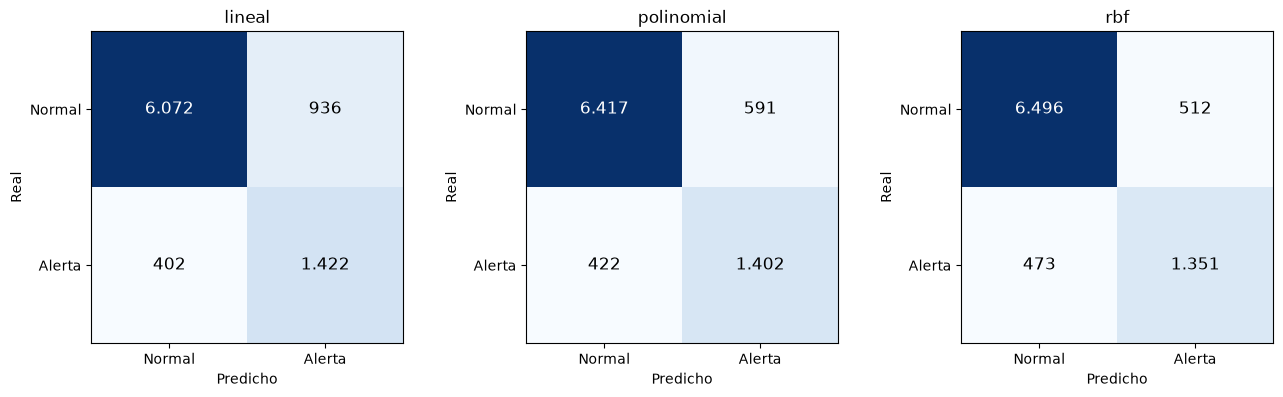

In [10]:
# Celda 9.2: SVM con hiperparámetros ajustados, reentrenados con todo el entrenamiento y evaluados en prueba
tabla_aj, modelos_aj, preds_aj = ms.comparar_kernels_holdout(X_tr, X_te, y_tr, y_te, parametros=mejores)
display(tabla_aj)

comp_aj = pd.concat({"Por defecto": tabla_ho[["Recall", "Precision", "F1", "AUC"]],
                     "Ajustado": tabla_aj[["Recall", "Precision", "F1", "AUC"]]}, axis=1)
display(comp_aj)
fig = gr.graficar_matrices_confusion(y_te, preds_aj)
plt.show()

**Cómo leer las tablas.** La primera lista, por kernel, las mejores combinaciones de hiperparámetros (hasta 5) según el F1 de la validación temporal (`mean_test_score` es el promedio de los folds). La segunda tabla evalúa en la prueba los SVM ajustados, y la tercera los compara con los de la sección 5 (por defecto). La figura final muestra las matrices de confusión de los tres SVM ajustados, que se leen igual que en la sección 5.

**Resultados.**

- **Mejores combinaciones:** lineal `C = 1` (F1 CV 0,787 ± 0,073), polinomial `C = 10` y grado 3 (0,801 ± 0,103) y RBF `C = 10` y `gamma = 0,3` (0,806 ± 0,106). Las diferencias entre kernels (menos de 0,02) son mucho menores que las desviaciones: **en validación no hay un ganador claro**.
- **Efecto en la prueba:**

| Kernel | F1 por defecto | F1 ajustado | AUC por defecto | AUC ajustado |
|---|---|---|---|---|
| Lineal | 0,680 | 0,680 | 0,898 | 0,898 |
| Polinomial | 0,721 | **0,735** | 0,922 | **0,931** |
| RBF | 0,703 | 0,733 | 0,906 | 0,827 |

- **El lineal no cambia**: el parámetro `C` casi no lo afecta (las 4 combinaciones de `C` de la tabla dieron F1 de 0,779 a 0,787).
- **El polinomial mejora en todo** (F1 de 0,721 a 0,735 y AUC de 0,922 a 0,931): con `C = 10` el modelo es algo más ajustado y sigue generalizando bien.
- **El RBF mejora el F1 pero empeora el AUC** (de 0,906 a 0,827) y baja el recall (de 0,790 a 0,741): con `gamma = 0,3` la frontera se vuelve muy local: el modelo casi memoriza el entrenamiento y pierde calidad al ordenar los casos del periodo de prueba (el Anexo B, opcional, lo comprueba). Además `gamma = 0,3` es el borde de la grilla, por lo que el óptimo podría estar más allá; con más tiempo habría que ampliarla.
- **Matrices de confusión (figura final).** Confirman lo anterior. El RBF ajustado emite menos falsas alarmas (512 frente a 591 del polinomial) pero deja pasar más cargas máximas (473 frente a 422): es el patrón de mayor precisión y menor recall de la tabla. El polinomial ajustado mejora a su versión por defecto en ambos errores (falsas alarmas de 649 a 591 y cargas máximas no avisadas de 430 a 422). El lineal es idéntico al de la sección 5 (936 y 402).

## 10. Conclusiones, limitaciones y próximos pasos

### 10.1 Qué kernel conviene

**Para el sistema de alertas conviene el SVM con kernel polinomial de grado 3** (con `C = 10`). La decisión se apoya en la convergencia de varias evidencias, no en una sola:

- Es el mejor en la **validación cruzada estratificada** (F1 0,853) y queda **empatado con el RBF en la temporal** (0,795 frente a 0,794; con desviaciones de 0,15). En esa validación, polinomial y RBF superan al lineal en 4 de los 5 folds.
- En la **prueba** es el mejor por defecto (F1 0,721, AUC 0,922) y **sigue siendo el mejor tras el ajuste** (F1 0,735, AUC 0,931). Frente al RBF ajustado el F1 es prácticamente igual (0,735 frente a 0,733), pero el polinomial anticipa más cargas máximas (recall 0,769 frente a 0,741), a cambio de una precisión algo menor (0,703 frente a 0,725) y con un AUC mucho mayor (0,931 frente a 0,827).
- Es **estable al ajustarlo**, mientras que el RBF ajustado pierde AUC en la prueba (el Anexo B muestra que con `gamma` alto memoriza el entrenamiento).
- Frente al lineal, la diferencia es la que muestra la sección 6: la carga máxima depende de la **combinación** de consumo y hora, algo que un plano recto no puede representar.

Un matiz de honestidad: el kernel se eligió por validación cruzada y el conjunto de prueba solo lo confirma; que ambos coincidan da confianza, pero que el polinomial y el RBF queden empatados en la validación temporal significa que **la elección entre ellos es menos firme que la distancia con el lineal**.

### 10.2 Qué aporta al proyecto

- **Un clasificador de alerta anticipada.** Con el polinomial ajustado, a 1 hora de anticipación el sistema avisa de **1.402 de las 1.824 cargas máximas** de la prueba (recall 0,77), y **de cada 10 alertas emitidas, 7 son reales** (precisión 0,70; 591 falsas alarmas en 8.832 casos). La persistencia, sin modelo, solo llega a 0,56 en ambas métricas.
- **Una medida honesta de su confiabilidad**, que permite decidir si la alerta es útil en la práctica o si las falsas alarmas la volverían molesta.

### 10.3 Lecciones metodológicas

- La validación cruzada **estratificada es optimista** en series de tiempo con lecturas cada 15 minutos (sobreestima el F1 en unos 0,13). La validación **temporal** es más honesta, aunque más ruidosa cuando el primer fold tiene poca historia.
- Elegir hiperparámetros solo por el puntaje de validación puede llevar a un modelo que memoriza el entrenamiento (caso del RBF; Anexo B), por lo que conviene mirar también el AUC en datos no vistos.

### 10.4 Limitaciones

- **Un solo año de datos** y una sola partición de prueba (tres meses): no se puede verificar que el comportamiento se repita en otras estaciones.
- La clase alerta es **minoritaria (21 %)**; se compensó con `class_weight="balanced"`, y el umbral de decisión quedó en el valor por defecto (`f(x) = 0`).
- La grilla de hiperparámetros es **pequeña**, y el mejor `gamma` del RBF cayó en su borde.
- El ajuste se hizo con una **submuestra** de 8.000 casos, por tiempo de cómputo.
- Las alertas se concentran en el horario diurno (sección 6) y el modelo no se evaluó por separado por tramo horario ni por día de la semana.

### 10.5 Próximos pasos

1. **Ajustar el umbral de decisión** según el costo de cada tipo de error: subir el recall si dejar pasar una carga máxima es más caro que una falsa alarma, o la precisión en el caso contrario.
2. **Ampliar la grilla** (en especial `gamma` del RBF) y probar horizontes distintos de 1 hora, como se hizo en la Tarea 4.

## 11. Anexos opcionales

Estos dos anexos **no forman parte de lo que pide la tarea** y pueden omitirse (cada uno tarda unos 2 a 3 minutos en ejecutarse). Comprueban con experimentos dos explicaciones del texto principal, y de ellos salen conclusiones útiles para el proyecto final: **con qué datos conviene entrenar el modelo de alerta** (Anexo A) y **con qué cuidado elegir sus hiperparámetros** (Anexo B). El código está en `src/SVM_CV/diagnosticos.py`.

### Anexo A. ¿Por qué rinde peor el primer fold de la validación temporal?

En la sección 8, el primer fold fue el peor para los tres kernels (el polinomial y el RBF cayeron a F1 de 0,53 y 0,55). Hay dos explicaciones posibles: (1) tiene **pocos casos** de entrenamiento, o (2) esas primeras semanas **no representan** al periodo que viene después. Se separan con dos pruebas:

- **A.1:** se compara el fold 1 real con un entrenamiento **del mismo tamaño** pero con casos tomados al azar del resto del año; ambos se validan en el mismo bloque. Si la causa fuera la cantidad de casos, el resultado no cambiaría.
- **A.2 (curva de aprendizaje):** se entrena con cantidades crecientes de casos (de enero a junio) y se valida siempre en julio a septiembre, para ver cuántos casos necesita cada kernel.

In [11]:
# Celda A.1: primer fold real vs. el mismo número de casos tomados al azar
from SVM_CV import diagnosticos as dg

tabla_f1, desc_f1 = dg.primer_fold_vs_azar(X_tr, y_tr, info["fecha_objetivo_tr"], k=K_FOLDS)
n_ent = f"{desc_f1['n_entrenamiento']:,}".replace(",", ".")
n_val = f"{desc_f1['n_validacion']:,}".replace(",", ".")
print(f"Fold 1: {n_ent} casos de entrenamiento ({desc_f1['entrena_desde']:%d-%m} al {desc_f1['entrena_hasta']:%d-%m}), "
      f"validado entre el {desc_f1['valida_desde']:%d-%m} y el {desc_f1['valida_hasta']:%d-%m} ({n_val} casos).")
display(tabla_f1)

Fold 1: 4.257 casos de entrenamiento (02-01 al 15-02), validado entre el 16-02 y el 02-04 (4.351 casos).


,Entrenamiento,Kernel,Recall,Precision,F1,AUC
0,Primeras semanas (fold real),lineal,0.861,0.503,0.635,0.896
1,"Mismo n, al azar del resto del año",lineal,0.875,0.685,0.769,0.930
2,Primeras semanas (fold real),polinomial,0.656,0.440,0.527,0.844
3,"Mismo n, al azar del resto del año",polinomial,0.847,0.708,0.771,0.895
4,Primeras semanas (fold real),rbf,0.705,0.448,0.548,0.826
5,"Mismo n, al azar del resto del año",rbf,0.862,0.667,0.752,0.943


Base de entrenamiento: 17.276 casos | bloque de validación: 8.832 casos (20.4 % alertas)


Kernel,lineal,polinomial,rbf
n,,,
300,0.815,0.800,0.805
600,0.841,0.835,0.832
1200,0.847,0.850,0.848
2400,0.853,0.861,0.862
4800,0.855,0.865,0.871
9600,0.856,0.872,0.877
17276,0.857,0.876,0.878


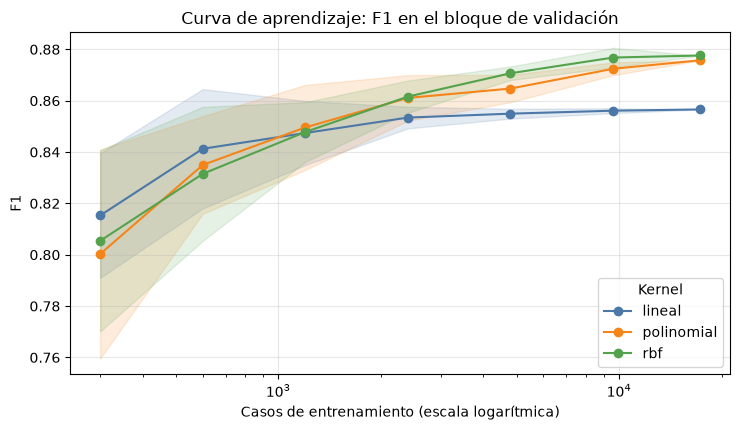

In [12]:
# Celda A.2: curva de aprendizaje (entrena con ene-jun, valida siempre en jul-sep)
curva = dg.curva_aprendizaje(X_tr, y_tr, info["fecha_objetivo_tr"])
print(f"Base de entrenamiento: {curva.attrs['n_base']:,} casos | bloque de validación: "
      f"{curva.attrs['n_validacion']:,} casos ({100 * curva.attrs['alerta_validacion']:.1f} % alertas)".replace(",", "."))
display(dg.resumen_curva_aprendizaje(curva, "F1"))
fig = gr.graficar_curva_aprendizaje(curva, "F1")
plt.show()

**Cómo leer los resultados.** En A.1, cada kernel aparece dos veces: entrenado con las primeras semanas (el fold real) y entrenado con el mismo número de casos tomados al azar del resto del año; la validación es idéntica. En A.2, cada fila es un número de casos de entrenamiento y cada columna un kernel; el gráfico muestra el promedio de 5 repeticiones (línea) y ± 1 desviación (banda).

**Resultados A.1** (fold 1: 4.257 casos, del 02-01 al 15-02, validado entre el 16-02 y el 02-04):

| Kernel | F1 con las primeras semanas | F1 con el mismo n, al azar |
|---|---|---|
| Lineal | 0,635 | 0,769 |
| Polinomial | 0,527 | 0,771 |
| RBF | 0,548 | 0,752 |

Con el mismo número de casos, los tres kernels suben a F1 de 0,75 a 0,77 y quedan parejos. Sube la precisión en los tres (de 0,44 a 0,50 hasta 0,67 a 0,71) y, en el polinomial y el RBF, también el recall. **La debilidad del fold 1 no se debe a la cantidad de casos sino a su cobertura en el tiempo**: las primeras semanas del año no representan bien lo que ocurre después, y un modelo entrenado solo con ellas emite muchas falsas alarmas.

**Resultados A.2** (F1 promedio; base de 17.276 casos, validación de 8.832 casos con 20,4 % de alertas):

| Casos de entrenamiento | Lineal | Polinomial | RBF |
|---|---|---|---|
| 300 | 0,815 | 0,800 | 0,805 |
| 600 | 0,841 | 0,835 | 0,832 |
| 1.200 | 0,847 | 0,850 | 0,848 |
| 2.400 | 0,853 | 0,861 | 0,862 |
| 4.800 | 0,855 | 0,865 | 0,871 |
| 9.600 | 0,856 | 0,872 | 0,877 |
| 17.276 | 0,857 | 0,876 | 0,878 |

- El lineal mejora poco y **se estanca cerca de 0,857 desde unos 2.400 casos**.
- El polinomial y el RBF **siguen mejorando con más datos** (hasta 0,876 y 0,878) y pasan al lineal entre 1.200 y 2.400 casos. Con 300 a 600 casos el lineal parte algo más arriba, pero esa diferencia es del tamaño de la variación entre repeticiones (± 0,02 a 0,04).
- Entrenando con enero a junio y validando en julio a septiembre, el F1 llega a 0,86 a 0,88; en la prueba de octubre a diciembre es de 0,68 a 0,72. Los entrenamientos no son idénticos (uno llega hasta junio y el otro hasta septiembre), así que esto es una señal, no una prueba, de que octubre a diciembre es un periodo más difícil.

**Qué implica para el proyecto final.**

1. **No basta con tener muchas lecturas: tienen que cubrir distintas épocas del año.** Con 4.257 casos concentrados en las primeras semanas el modelo falla; con la misma cantidad repartida en el año funciona bien.
2. **Con unos 2.400 casos bien repartidos, los kernels curvos ya superan al lineal, y siguen mejorando con más datos mientras el lineal no.** Eso refuerza la elección de un kernel curvo para el modelo final.
3. **El desempeño cambia según el periodo**, por lo que conviene informar el resultado como un rango (por ejemplo, F1 de 0,68 a 0,88 según el periodo) y evaluar el modelo en periodos nuevos antes de confiar en él.

### Anexo B. ¿El RBF con `gamma` alto memoriza el entrenamiento?

En la sección 9, el RBF ajustado (`C = 10`, `gamma = 0,3`) mejoró su F1 pero su AUC en prueba cayó de 0,906 a 0,827. La hipótesis es que con `gamma` alto el modelo **memoriza** el entrenamiento (cada punto influye solo en su entorno inmediato) y generaliza peor. Se comprueba con dos pruebas, fijando `C = 10` y variando `gamma`:

- **B.1 (curva de validación):** se compara el puntaje de **entrenamiento** con el de **validación** (validación cruzada temporal, solo con datos de entrenamiento, sin usar la prueba). Una brecha grande entre ambos indica memorización.
- **B.2 (diagnóstico en prueba):** el mismo barrido medido en la prueba. **Es solo un diagnóstico: la prueba no se usa para elegir `gamma`.**

Entrenamiento       Validacion       Brecha       
Metrica           AUC    F1        AUC    F1    AUC     F1
gamma                                                     
0.005           0.942 0.714      0.947 0.763 -0.005 -0.049
0.010           0.955 0.735      0.946 0.772  0.009 -0.037
0.050           0.980 0.821      0.943 0.793  0.038  0.028
0.100           0.987 0.880      0.946 0.798  0.041  0.082
0.300           0.996 0.944      0.944 0.806  0.052  0.138
1.000           1.000 0.989      0.945 0.773  0.055  0.215

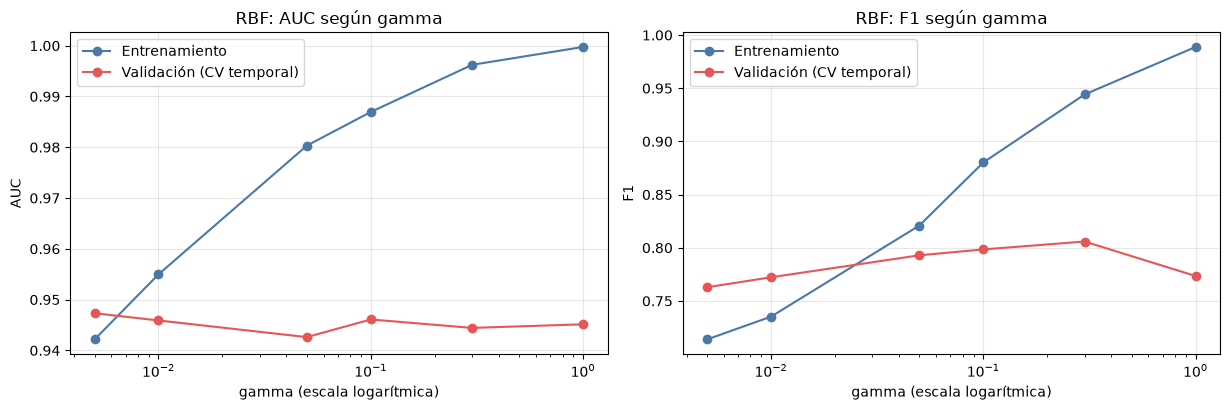

In [13]:
# Celda B.1: curva de validación de gamma (CV temporal, solo con datos de entrenamiento)
cv_gamma = dg.curva_validacion_gamma(X_tr, y_tr)
display(cv_gamma.pivot(index="gamma", columns="Metrica", values=["Entrenamiento", "Validacion", "Brecha"]))
fig = gr.graficar_curva_validacion_gamma(cv_gamma)
plt.show()

In [14]:
# Celda B.2: el mismo barrido evaluado en la prueba (solo diagnóstico)
diag_gamma = dg.diagnostico_gamma_en_prueba(X_tr, X_te, y_tr, y_te)
display(diag_gamma)

,AUC_entrenamiento,AUC_prueba,F1_entrenamiento,F1_prueba,Recall_prueba,Precision_prueba
gamma,,,,,,
0.010,0.974,0.916,0.803,0.696,0.797,0.617
0.050,0.982,0.917,0.870,0.733,0.783,0.689
scale,0.987,0.895,0.882,0.725,0.755,0.697
0.300,0.998,0.827,0.936,0.733,0.741,0.725
1.000,0.999,0.813,0.988,0.716,0.675,0.763


**Cómo leer los resultados.** En B.1, `Brecha` es el puntaje de entrenamiento menos el de validación: si crece con `gamma`, el modelo se ajusta cada vez más a los datos que vio. En B.2, la columna `gamma = scale` equivale a unos 0,077.

**Resultados B.1** (validación cruzada temporal, submuestra de 8.000 casos):

| gamma | AUC entrenamiento | AUC validación | Brecha AUC | F1 entrenamiento | F1 validación |
|---|---|---|---|---|---|
| 0,005 | 0,942 | 0,947 | −0,005 | 0,714 | 0,763 |
| 0,05 | 0,980 | 0,943 | 0,038 | 0,821 | 0,793 |
| 0,3 | 0,996 | 0,944 | 0,052 | 0,944 | 0,806 |
| 1,0 | 1,000 | 0,945 | 0,055 | 0,989 | 0,773 |

- **El modelo memoriza:** al subir `gamma`, el AUC de entrenamiento llega a 1,0 y el F1 de entrenamiento a 0,99, mientras que en validación el AUC queda plano (alrededor de 0,945) y el F1 sube hasta 0,806 (con `gamma = 0,3`) y luego baja a 0,773. Eso es sobreajuste en sentido técnico: la brecha entre entrenamiento y validación crece sin que la validación mejore.
- **La validación no alcanza a ver la pérdida de AUC.** Dentro del periodo de entrenamiento, el AUC de validación no baja con `gamma`; la caída aparece recién en la prueba (B.2).

**Resultados B.2** (RBF con `C = 10`, medido en la prueba):

| gamma | AUC entrenamiento | AUC prueba | F1 entrenamiento | F1 prueba | Recall prueba | Precisión prueba |
|---|---|---|---|---|---|---|
| 0,01 | 0,974 | 0,916 | 0,803 | 0,696 | 0,797 | 0,617 |
| 0,05 | 0,982 | 0,917 | 0,870 | 0,733 | 0,783 | 0,689 |
| scale | 0,987 | 0,895 | 0,882 | 0,725 | 0,755 | 0,697 |
| 0,3 | 0,998 | 0,827 | 0,936 | 0,733 | 0,741 | 0,725 |
| 1,0 | 0,999 | 0,813 | 0,988 | 0,716 | 0,675 | 0,763 |

Con `gamma` creciente, el AUC de prueba pasa de 0,917 a 0,813 mientras el de entrenamiento se acerca a 1,0. El F1 de prueba casi no cambia entre `gamma = 0,05` y `0,3` (0,733 en ambos), por eso **el F1 por sí solo no detectó el problema**: lo que empeora es el orden en que el modelo clasifica los casos (AUC) y el recall.

**Qué implica para el proyecto final.**

1. **Para el modelo final, conviene un `gamma` moderado.** En esta prueba, `gamma = 0,05` da el mismo F1 que `0,3` con un AUC mucho mejor (0,917 frente a 0,827). Como esta prueba ya se usó para diagnosticar, ese valor es un punto de partida que habría que confirmar con datos nuevos y no una elección definitiva.
2. **Elegir hiperparámetros solo por F1 es riesgoso.** Conviene acompañarlo del AUC y de una evaluación en un periodo posterior al del entrenamiento.
3. **El polinomial es menos sensible a este problema**: tras el ajuste mejoró F1 y AUC (sección 9), por lo que sigue siendo la opción más segura para el modelo final.